# Customer Segmentation Using K-Means Clustering
## Minor Project – Artificial Intelligence & Machine Learning

**Objective:** Segment mall customers using annual income and spending score with K-Means clustering.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Google Colab.

**Dataset:** Mall Customer Segmentation Data (`Mall_Customers.csv`) from Kaggle.


## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load the dataset

In [2]:
# Try the public CSV source first; upload the Kaggle CSV if the download fails.
csv_url = "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning-A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2025%20-%20Hierarchical%20Clustering/Mall_Customers.csv"

try:
    df = pd.read_csv(csv_url)
    print("Dataset loaded from the public CSV source.")
except Exception as e:
    print("Automatic download failed:", e)
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise ValueError("No file was uploaded.")
        file_name = next(iter(uploaded))
        df = pd.read_csv(file_name)
        print("Dataset uploaded and loaded successfully.")
    except ImportError:
        raise RuntimeError(
            "Could not download the dataset. Upload Mall_Customers.csv "
            "and replace this cell with: df = pd.read_csv('Mall_Customers.csv')"
        )

df.columns = df.columns.str.strip()
print("Dataset shape:", df.shape)
display(df.head())

Automatic download failed: HTTP Error 404: Not Found


Saving Mall_Customers 2.csv to Mall_Customers 2.csv
Dataset uploaded and loaded successfully.
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Understand the dataset

In [3]:
display(df.head())
display(df.tail())
print("Columns:", df.columns.tolist())
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.info()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Rows: 200
Columns: 5
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


## 4. Data cleaning and preprocessing

In [4]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Customer IDs:", df["CustomerID"].duplicated().sum())
display(df.describe(include="all"))

required_columns = [
    "CustomerID", "Gender", "Age",
    "Annual Income (k$)", "Spending Score (1-100)"
]
missing_columns = set(required_columns) - set(df.columns)
assert not missing_columns, f"Missing columns: {missing_columns}"

df = df.drop_duplicates().copy()
print("\nDataset shape after cleaning:", df.shape)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0
Duplicate Customer IDs: 0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000



Dataset shape after cleaning: (200, 5)


## 5. Exploratory Data Analysis (EDA)

### 5.1 Gender distribution

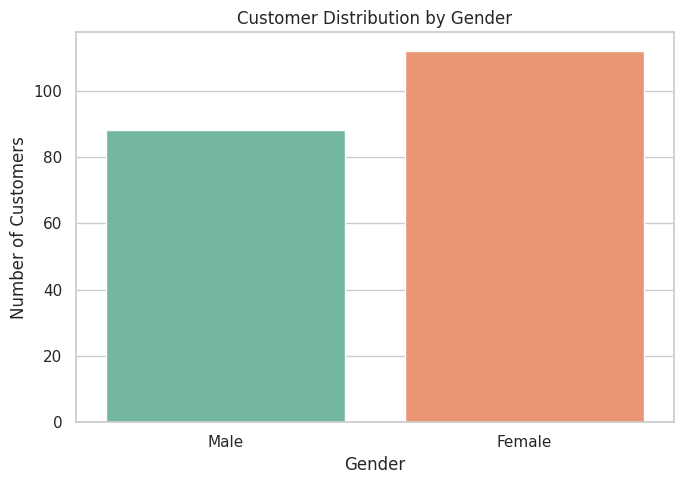

In [5]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender", hue="Gender", palette="Set2", legend=False)
plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### 5.2 Age distribution

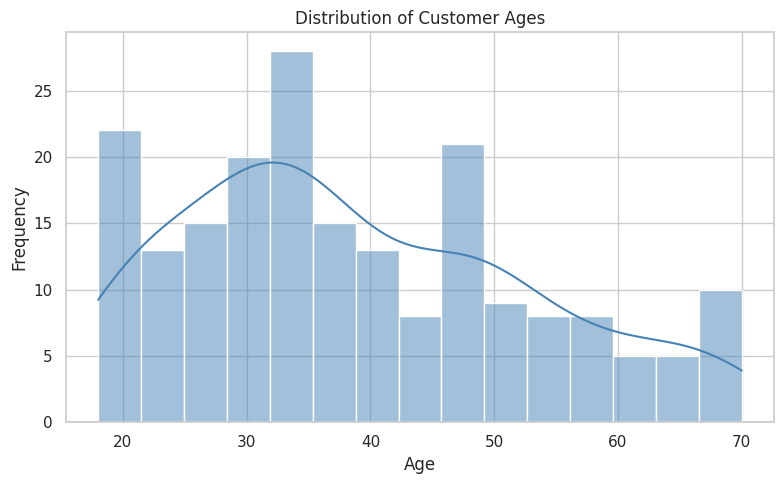

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=15, kde=True, color="steelblue")
plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 5.3 Annual income distribution

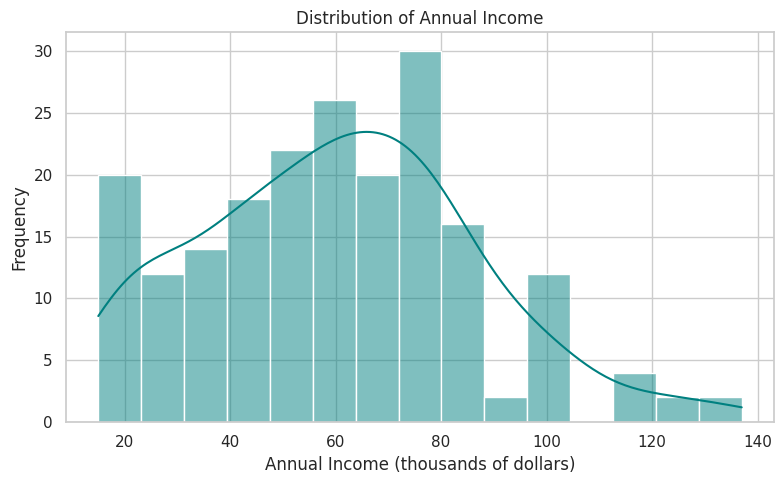

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Annual Income (k$)", bins=15, kde=True, color="teal")
plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 5.4 Spending score distribution

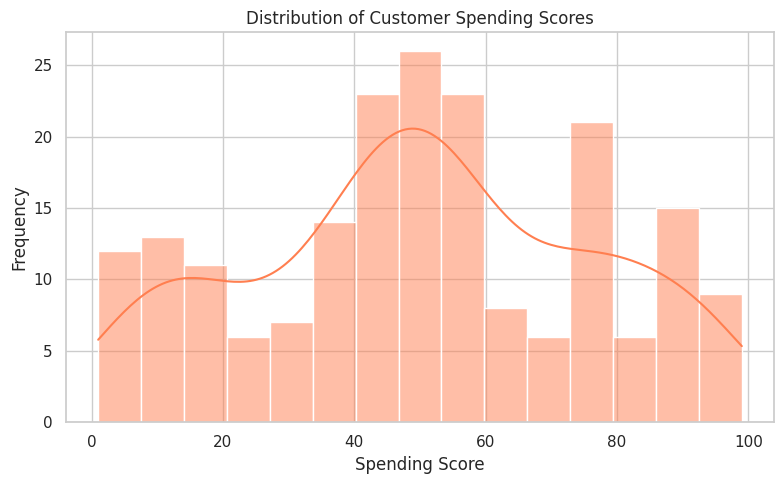

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Spending Score (1-100)", bins=15, kde=True, color="coral")
plt.title("Distribution of Customer Spending Scores")
plt.xlabel("Spending Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 5.5 Correlation heatmap

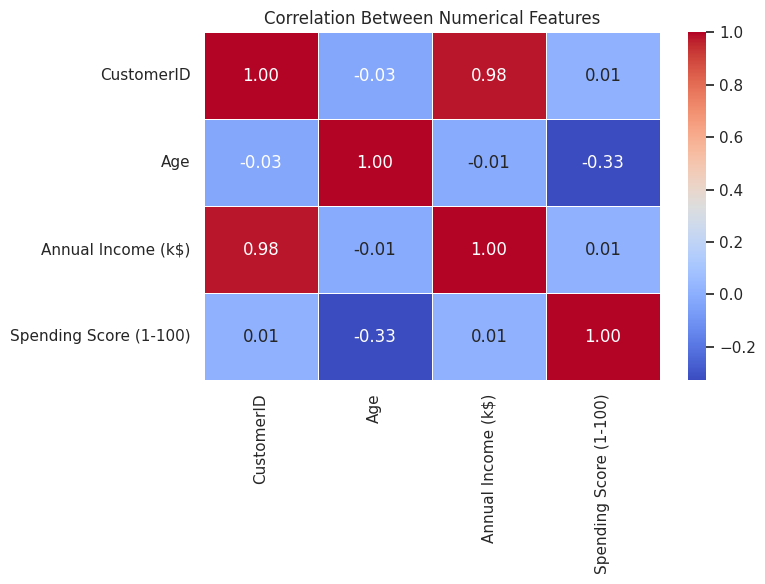

In [9]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

## 6. Select features for K-Means

In [10]:
# CustomerID is an identifier, so it is excluded from clustering.
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()
print("Features selected:")
display(X.head())
print("Feature matrix shape:", X.shape)

Features selected:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Feature matrix shape: (200, 2)


### Visualize the original customer data

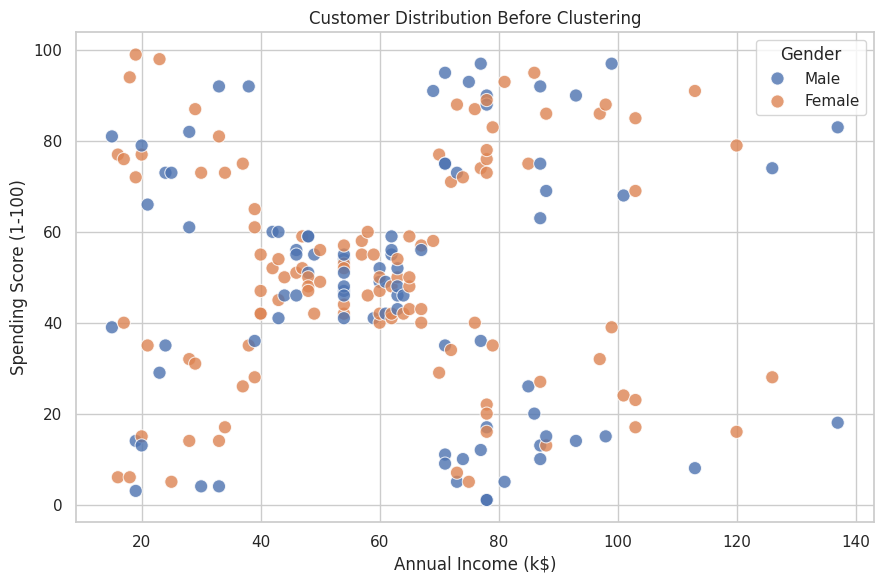

In [11]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
    hue="Gender", s=90, alpha=0.8
)
plt.title("Customer Distribution Before Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

## 7. Feature scaling

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
display(X_scaled_df.head())
print("Mean after scaling:")
print(X_scaled_df.mean().round(2))
print("\nStandard deviation after scaling:")
print(X_scaled_df.std(ddof=0).round(2))

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


Mean after scaling:
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standard deviation after scaling:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


## 8. Find the number of clusters using the Elbow Method

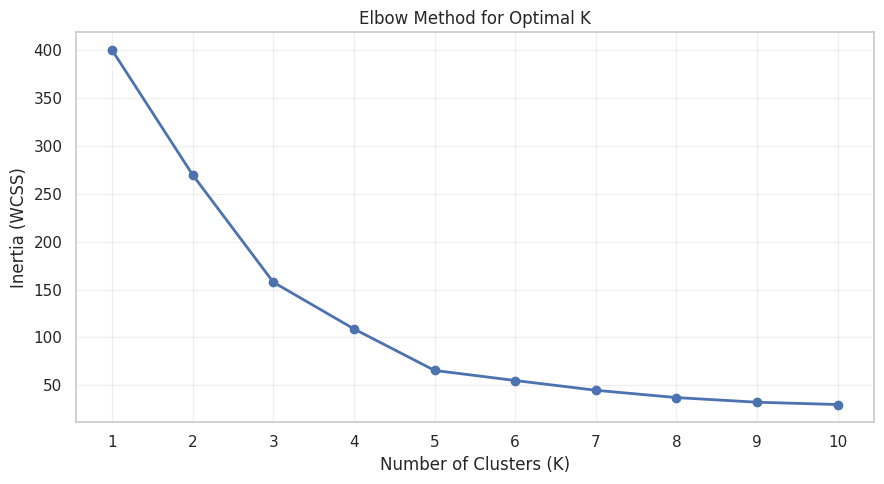

In [13]:
inertia_values = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertia_values, marker="o", linewidth=2)
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Evaluate clusters using silhouette scores

,Number of Clusters,Silhouette Score
0,5,0.554657
1,6,0.539880
2,7,0.528149
3,4,0.493907
4,3,0.466585
5,9,0.457085
6,8,0.455215
7,10,0.443171
8,2,0.321271


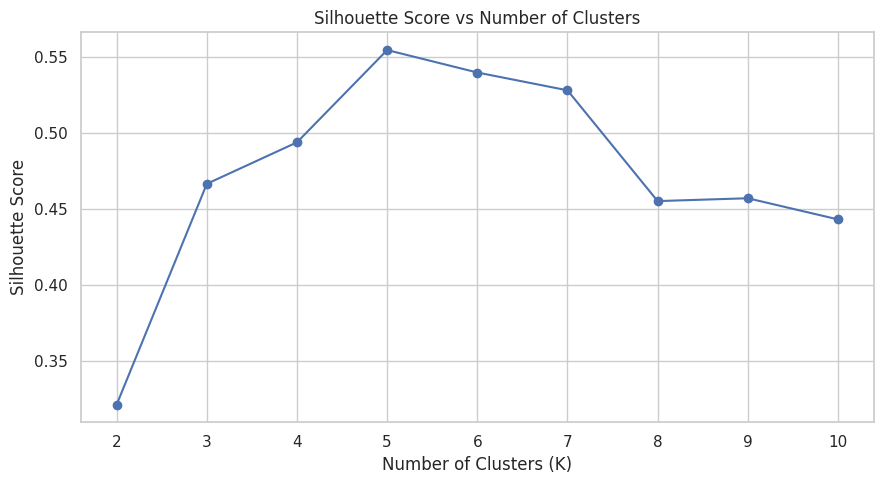

In [14]:
silhouette_results = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_results.append({
        "Number of Clusters": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df.sort_values("Silhouette Score", ascending=False).reset_index(drop=True))

plt.figure(figsize=(9, 5))
plt.plot(
    silhouette_df["Number of Clusters"],
    silhouette_df["Silhouette Score"],
    marker="o"
)
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.tight_layout()
plt.show()

## 10. Train the final K-Means model

In [15]:
# Five clusters is a common starting point for this teaching dataset.
# Revisit this value after inspecting the Elbow and Silhouette plots.
optimal_k = 5

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
final_silhouette = silhouette_score(X_scaled, df["Cluster"])

print("K-Means model trained successfully!")
print("Number of clusters:", optimal_k)
print("Silhouette score:", round(final_silhouette, 3))
print("\nCustomers per cluster:")
print(df["Cluster"].value_counts().sort_index())

K-Means model trained successfully!
Number of clusters: 5
Silhouette score: 0.555

Customers per cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


## 11. Visualize the final customer segments

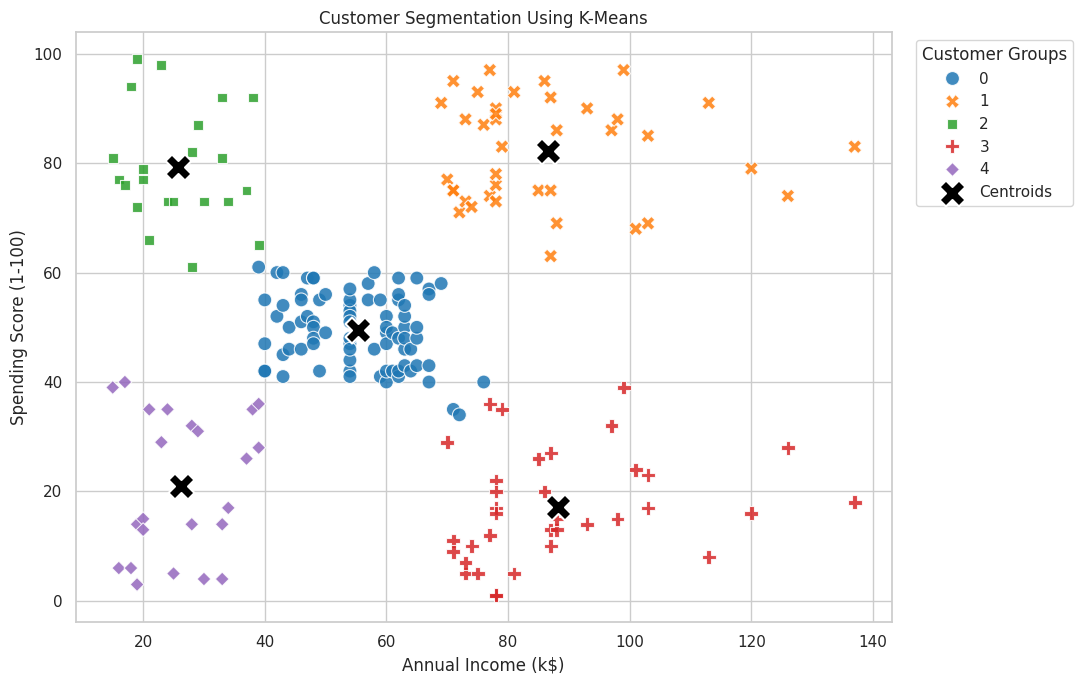

In [16]:
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=X.columns)

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
    hue="Cluster", palette="tab10", s=100, alpha=0.85, style="Cluster"
)
plt.scatter(
    centers_df["Annual Income (k$)"],
    centers_df["Spending Score (1-100)"],
    marker="X", s=350, c="black", edgecolor="white",
    linewidth=1.5, label="Centroids"
)
plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Groups", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 12. Analyze customer groups

### 12.1 Cluster profiles

In [17]:
cluster_profiles = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_profiles["Customer_Percentage"] = (
    cluster_profiles["Customer_Count"] / len(df) * 100
).round(2)

display(cluster_profiles)

,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score,Customer_Percentage
Cluster,,,,,
0,81,42.72,55.30,49.52,40.5
1,39,32.69,86.54,82.13,19.5
2,22,25.27,25.73,79.36,11.0
3,35,41.11,88.20,17.11,17.5
4,23,45.22,26.30,20.91,11.5


### 12.2 Compare average income and spending score

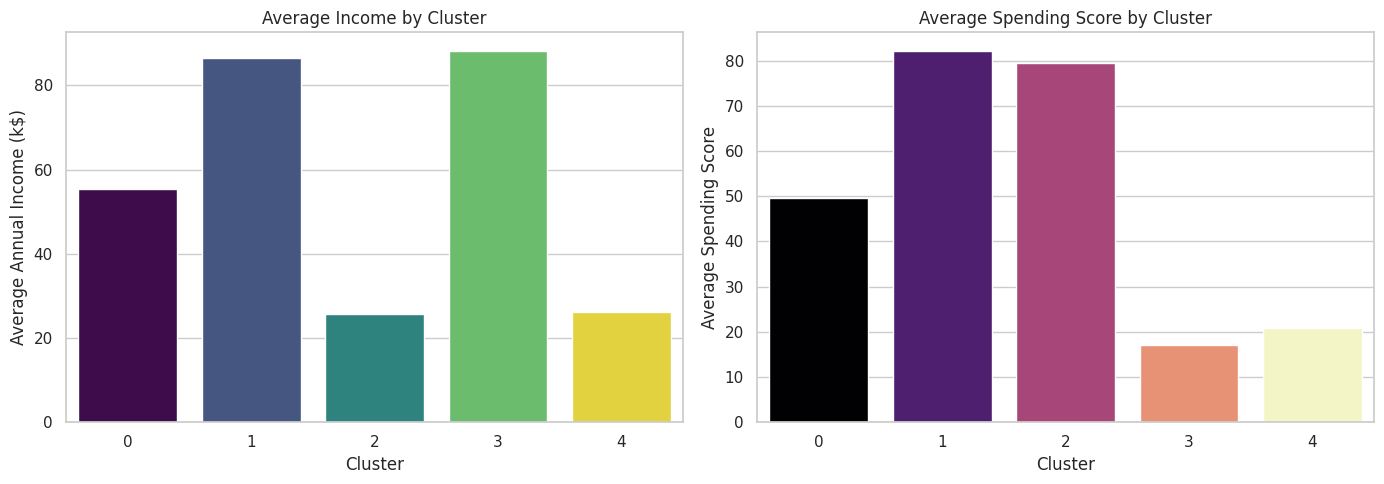

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df, x="Cluster", y="Annual Income (k$)", hue="Cluster",
    estimator="mean", errorbar=None, palette="viridis",
    legend=False, ax=axes[0]
)
axes[0].set_title("Average Income by Cluster")
axes[0].set_ylabel("Average Annual Income (k$)")

sns.barplot(
    data=df, x="Cluster", y="Spending Score (1-100)", hue="Cluster",
    estimator="mean", errorbar=None, palette="magma",
    legend=False, ax=axes[1]
)
axes[1].set_title("Average Spending Score by Cluster")
axes[1].set_ylabel("Average Spending Score")

plt.tight_layout()
plt.show()

### 12.3 Gender distribution within clusters

Gender,Female,Male
Cluster,,
0,59.26,40.74
1,53.85,46.15
2,59.09,40.91
3,45.71,54.29
4,60.87,39.13


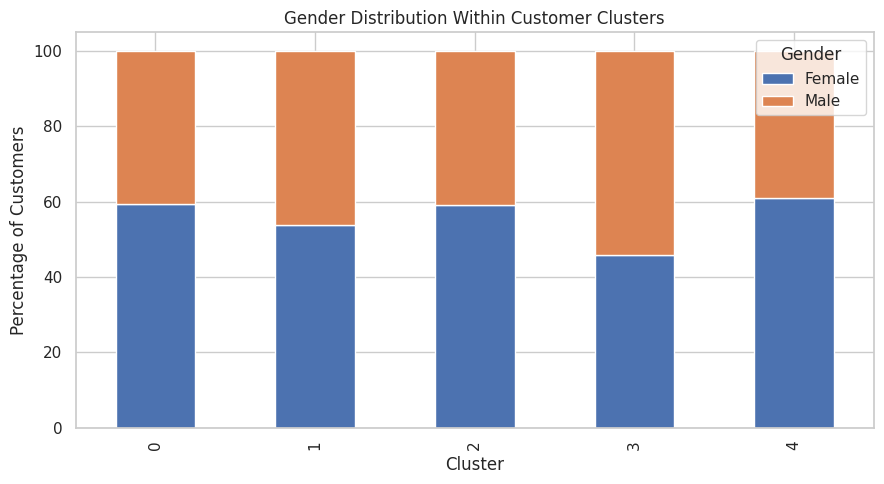

In [19]:
gender_distribution = pd.crosstab(
    df["Cluster"], df["Gender"], normalize="index"
).mul(100).round(2)

display(gender_distribution)
gender_distribution.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Gender Distribution Within Customer Clusters")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Customers")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

## 13. Give clusters business-friendly names

In [20]:
def name_cluster(row):
    income = row["Average_Annual_Income"]
    spending = row["Average_Spending_Score"]

    high_income = income >= cluster_profiles["Average_Annual_Income"].median()
    high_spending = spending >= cluster_profiles["Average_Spending_Score"].median()

    if high_income and high_spending:
        return "High-Income, High-Spending"
    elif high_income and not high_spending:
        return "High-Income, Low-Spending"
    elif not high_income and high_spending:
        return "Lower-Income, High-Spending"
    else:
        return "Lower-Income, Low-Spending"

cluster_profiles["Segment_Name"] = cluster_profiles.apply(name_cluster, axis=1)
display(cluster_profiles)

,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score,Customer_Percentage,Segment_Name
Cluster,,,,,,
0,81,42.72,55.30,49.52,40.5,"High-Income, High-Spending"
1,39,32.69,86.54,82.13,19.5,"High-Income, High-Spending"
2,22,25.27,25.73,79.36,11.0,"Lower-Income, High-Spending"
3,35,41.11,88.20,17.11,17.5,"High-Income, Low-Spending"
4,23,45.22,26.30,20.91,11.5,"Lower-Income, Low-Spending"


### Possible marketing interpretations

| Segment pattern | Possible strategy |
|---|---|
| High income, high spending | Loyalty benefits and premium offers |
| High income, low spending | Personalized offers to encourage engagement |
| Lower income, high spending | Reward programs and relevant promotions |
| Lower income, low spending | Value deals and budget-friendly offers |

These are simplified interpretations, not guaranteed predictions. Cluster IDs are arbitrary and names should be checked against the actual cluster profiles.

## 14. Export the segmented dataset

In [21]:
output_file = "Customer_Segmentation_Results.csv"
df.to_csv(output_file, index=False)
print("Export completed:", output_file)

# In Google Colab, this downloads the results to your computer.
try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("Outside Colab: find the CSV in the current working directory.")

Export completed: Customer_Segmentation_Results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Final project summary and conclusion

In [22]:
print("=" * 55)
print("CUSTOMER SEGMENTATION PROJECT SUMMARY")
print("=" * 55)
print("Total customers:", len(df))
print("Number of clusters:", optimal_k)
print("Silhouette score:", round(final_silhouette, 3))
print("Features used:", list(X.columns))
print("\nCustomers per segment:")
print(cluster_profiles[["Customer_Count", "Segment_Name"]])
print("\nProject completed successfully!")

CUSTOMER SEGMENTATION PROJECT SUMMARY
Total customers: 200
Number of clusters: 5
Silhouette score: 0.555
Features used: ['Annual Income (k$)', 'Spending Score (1-100)']

Customers per segment:
         Customer_Count                 Segment_Name
Cluster                                             
0                    81   High-Income, High-Spending
1                    39   High-Income, High-Spending
2                    22  Lower-Income, High-Spending
3                    35    High-Income, Low-Spending
4                    23   Lower-Income, Low-Spending

Project completed successfully!


## Conclusion

K-Means clustering was used to group mall customers by annual income and spending score. Exploratory data analysis helped describe the data, while the Elbow Method and silhouette score supported choosing a suitable number of clusters.

The resulting segments can help explore targeted marketing strategies and spending patterns. This is a small educational dataset, so the findings should be validated before real-world use.

### Viva preparation
Be ready to explain:
1. Why `CustomerID` is excluded from clustering.
2. Why feature scaling is used.
3. How K-Means assigns clusters and what a centroid represents.
4. How the Elbow Method and silhouette score help evaluate clustering.